**ANOMALY DETECTION OC-SVM**

In [2]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [3]:
job_names = ["net_v3_0per", "net_v3_20per", "net_v3_40per", "net_v3_60per", "net_v3_80per"]

def load_job(job_name):
    results_dir = f"/tmp/anomaly_results_md_{job_name}"          
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_md_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []        
all_rules = {}      

for job_name in job_names:
    results, df = load_job(job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "job_name": job_name,
        "min_flood_area": results["min_flood_area"],
        "standardize": results["standardize"],
        "n_fit": results["n_fit"], "n_normali": results["n_normali"], "n_anomale": results["n_anomale"],
        "score_normali": f"{score_normal.mean():.4f} ± {score_normal.std():.4f}",
        "score_anomale": f"{score_anom.mean():.4f} ± {score_anom.std():.4f}",
        "auroc": results["auroc"],
    })
    all_rules[job_name] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index("job_name")
df_rules = pd.concat(all_rules, names=["job_name", "regola"])     

df_summary

,min_flood_area,standardize,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc
job_name,,,,,,,,
net_v3_0per,0.0,True,2572,2402,2402,-291.6779 ± 330.4565,-388.5196 ± 2203.5078,0.710829
net_v3_20per,20.0,True,2572,1085,1085,-282.4363 ± 137.2393,-395.8352 ± 154.2115,0.815498
net_v3_40per,40.0,True,2572,642,642,-282.0256 ± 131.5283,-431.1521 ± 157.5298,0.867521
net_v3_60per,60.0,True,2572,359,359,-283.9565 ± 156.0799,-472.0210 ± 172.8981,0.907682
net_v3_80per,80.0,True,2572,173,173,-269.1668 ± 76.2053,-536.4582 ± 205.0182,0.955127


In [4]:
df_rules

soglia      TP     FP      FN  \
job_name     regola                                                          
net_v3_0per  md score < soglia (FA 5%)  -423.080209   387.0   62.0  2015.0   
             md score < soglia (FA 10%) -372.668424   676.0  104.0  1726.0   
             md score < soglia (FA 15%) -338.706003   945.0  183.0  1457.0   
             md score < soglia (FA 20%) -320.930848  1134.0  234.0  1268.0   
             md score < soglia (FA 25%) -305.564461  1294.0  286.0  1108.0   
             md score < soglia (FA 30%) -290.812020  1473.0  359.0   929.0   
net_v3_20per md score < soglia (FA 5%)  -418.678518   352.0   26.0   733.0   
             md score < soglia (FA 10%) -360.297864   558.0   57.0   527.0   
             md score < soglia (FA 15%) -338.539344   647.0   89.0   438.0   
             md score < soglia (FA 20%) -319.885653   733.0  122.0   352.0   
             md score < soglia (FA 25%) -307.296335   782.0  137.0   303.0   
             md score < soglia (FA 30%) -291.638984   850.0  167.0   235.0   
net_v3_40per md score < soglia (FA 5%)  -425.068871   266.0   17.0   376.0   
             md score < soglia (FA 10%) -361.070352   411.0   35.0   231.0   
             md score < soglia (FA 15%) -337.865352   465.0   59.0   177.0   
             md score < soglia (FA 20%) -319.883592   513.0   73.0   129.0   
             md score < soglia (FA 25%) -306.626629   534.0   80.0   108.0   
             md score < soglia (FA 30%) -295.307833   557.0   92.0    85.0   
net_v3_60per md score < soglia (FA 5%)  -419.367059   206.0   10.0   153.0   
             md score < soglia (FA 10%) -357.657308   276.0   21.0    83.0   
             md score < soglia (FA 15%) -336.774546   298.0   26.0    61.0   
             md score < soglia (FA 20%) -319.572370   314.0   33.0    45.0   
             md score < soglia (FA 25%) -306.691400   320.0   42.0    39.0   
             md score < soglia (FA 30%) -294.273641   331.0   50.0    28.0   
net_v3_80per md score < soglia (FA 5%)  -423.192510   123.0    1.0    50.0   
             md score < soglia (FA 10%) -365.163300   147.0    5.0    26.0   
             md score < soglia (FA 15%) -344.894299   152.0    7.0    21.0   
             md score < soglia (FA 20%) -331.785932   160.0    7.0    13.0   
             md score < soglia (FA 25%) -310.104039   166.0   11.0     7.0   
             md score < soglia (FA 30%) -299.605160   167.0   12.0     6.0   

                                             TN   FA_rate   MA_rate       REC  \
job_name     regola                                                             
net_v3_0per  md score < soglia (FA 5%)   1139.0  0.051624  0.838884  0.161116   
             md score < soglia (FA 10%)  1097.0  0.086595  0.718568  0.281432   
             md score < soglia (FA 15%)  1018.0  0.152373  0.606578  0.393422   
             md score < soglia (FA 20%)   967.0  0.194838  0.527893  0.472107   
             md score < soglia (FA 25%)   915.0  0.238135  0.461282  0.538718   
             md score < soglia (FA 30%)   842.0  0.298918  0.386761  0.613239   
net_v3_20per md score < soglia (FA 5%)    517.0  0.047882  0.675576  0.324424   
             md score < soglia (FA 10%)   486.0  0.104972  0.485714  0.514286   
             md score < soglia (FA 15%)   454.0  0.163904  0.403687  0.596313   
             md score < soglia (FA 20%)   421.0  0.224678  0.324424  0.675576   
             md score < soglia (FA 25%)   406.0  0.252302  0.279263  0.720737   
             md score < soglia (FA 30%)   376.0  0.307551  0.216590  0.783410   
net_v3_40per md score < soglia (FA 5%)    304.0  0.052960  0.585670  0.414330   
             md score < soglia (FA 10%)   286.0  0.109034  0.359813  0.640187   
             md score < soglia (FA 15%)   262.0  0.183801  0.275701  0.724299   
             md score < soglia (FA 20%)   248.0  0.227414  0.200935  0.799065   
             md score < soglia (FA 25%)   241.0  0.249221  0.168224  0.831776   
         

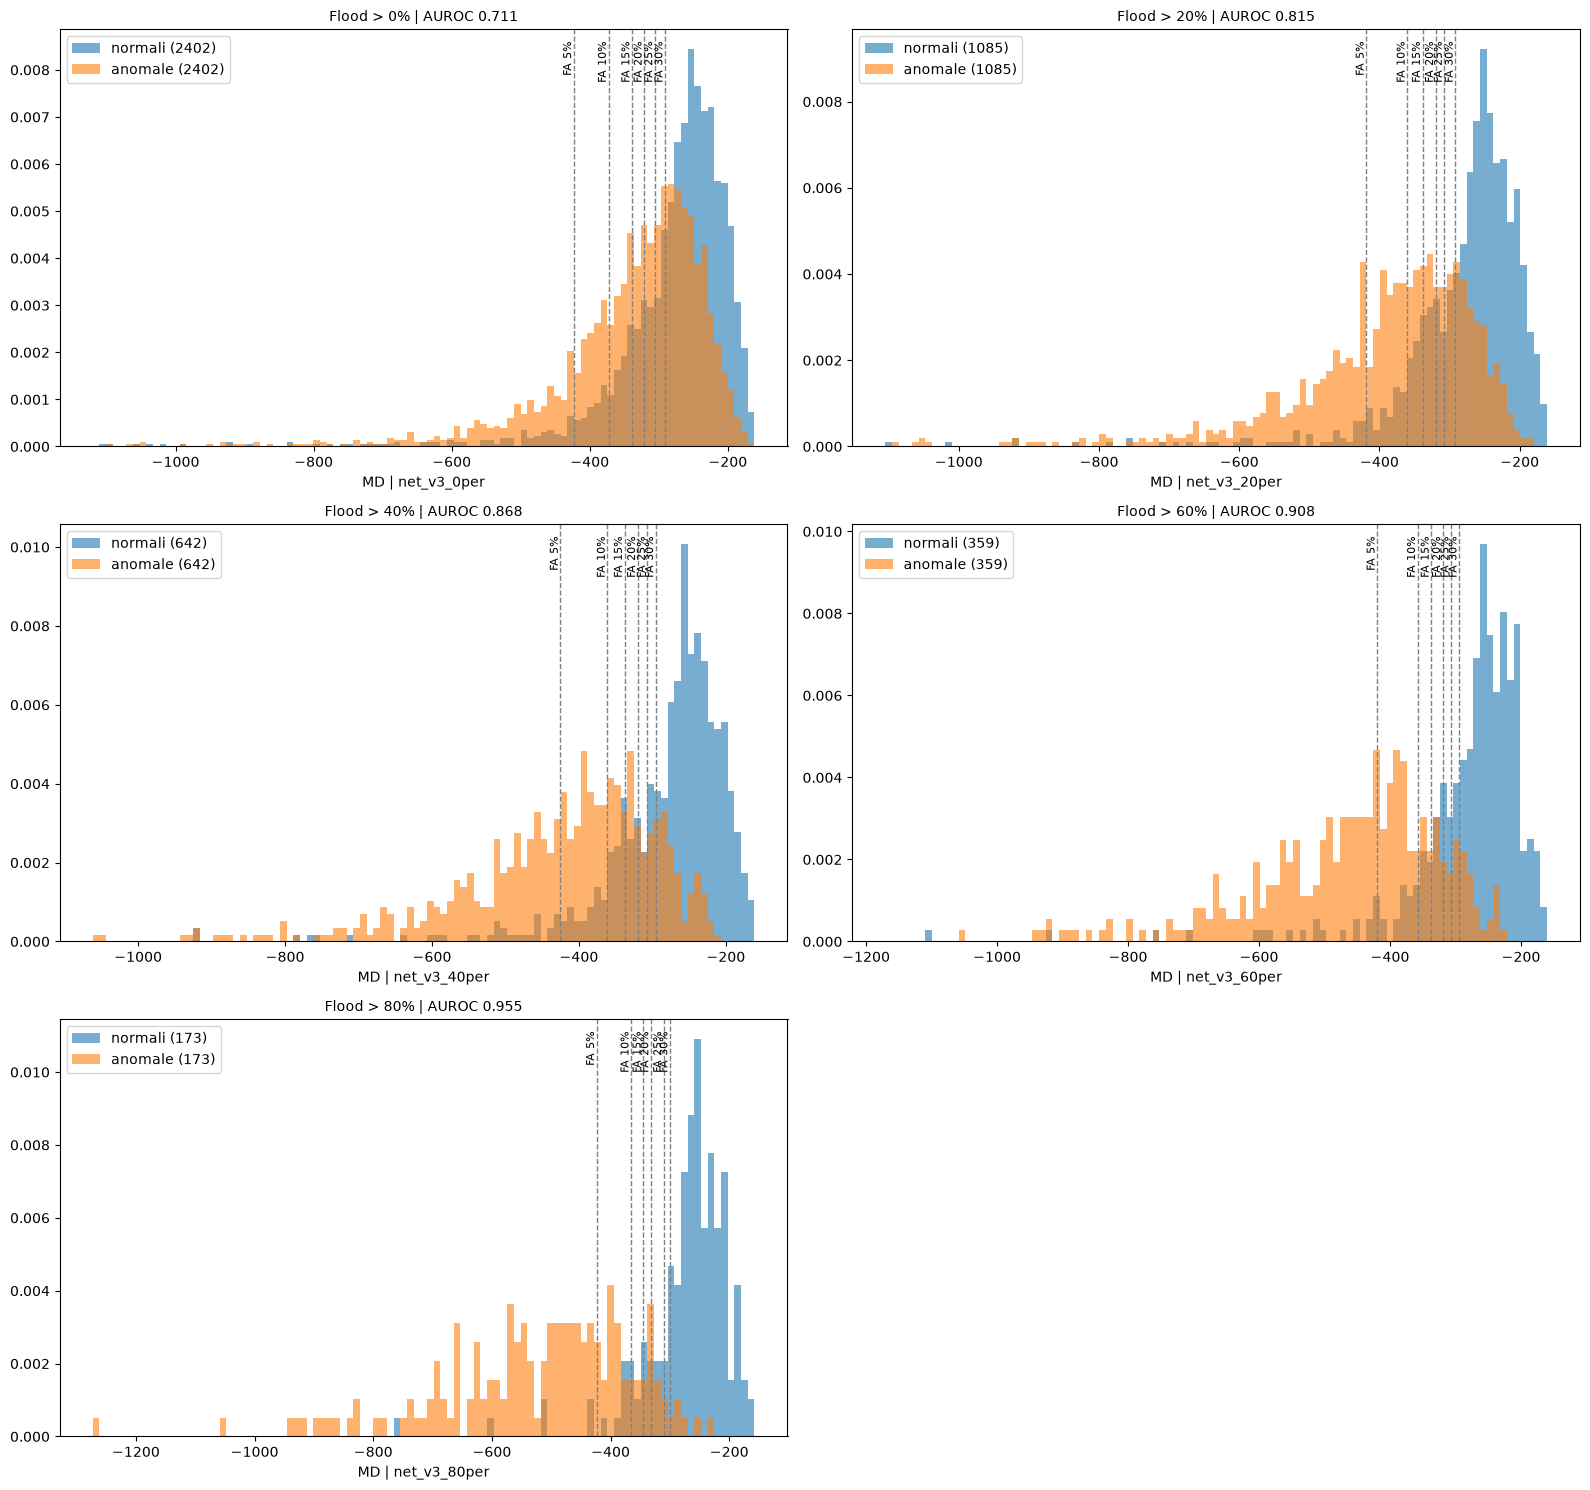

In [5]:
def plot_hist(ax, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])               
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
    for nome, r in results["rules"].items():                     
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)
    ax.set_xlabel(f"MD | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=10)


n_cols = 2
n_rows = int(np.ceil(len(job_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, job_name in zip(axes.flat, job_names):
    results, df = load_job(job_name)
    plot_hist(ax, job_name, results, df)

for ax in axes.flat[len(job_names):]:                           
    ax.axis("off")

plt.tight_layout()
plt.show()

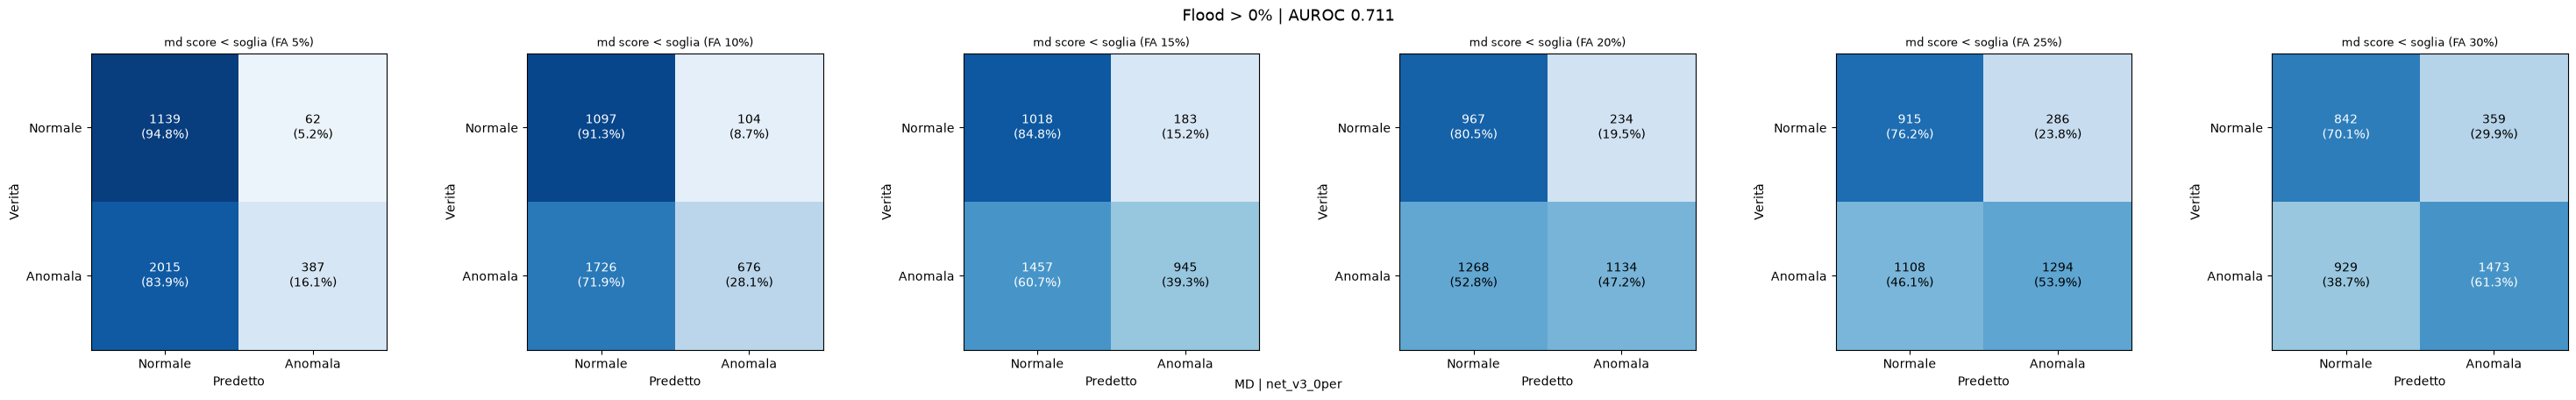

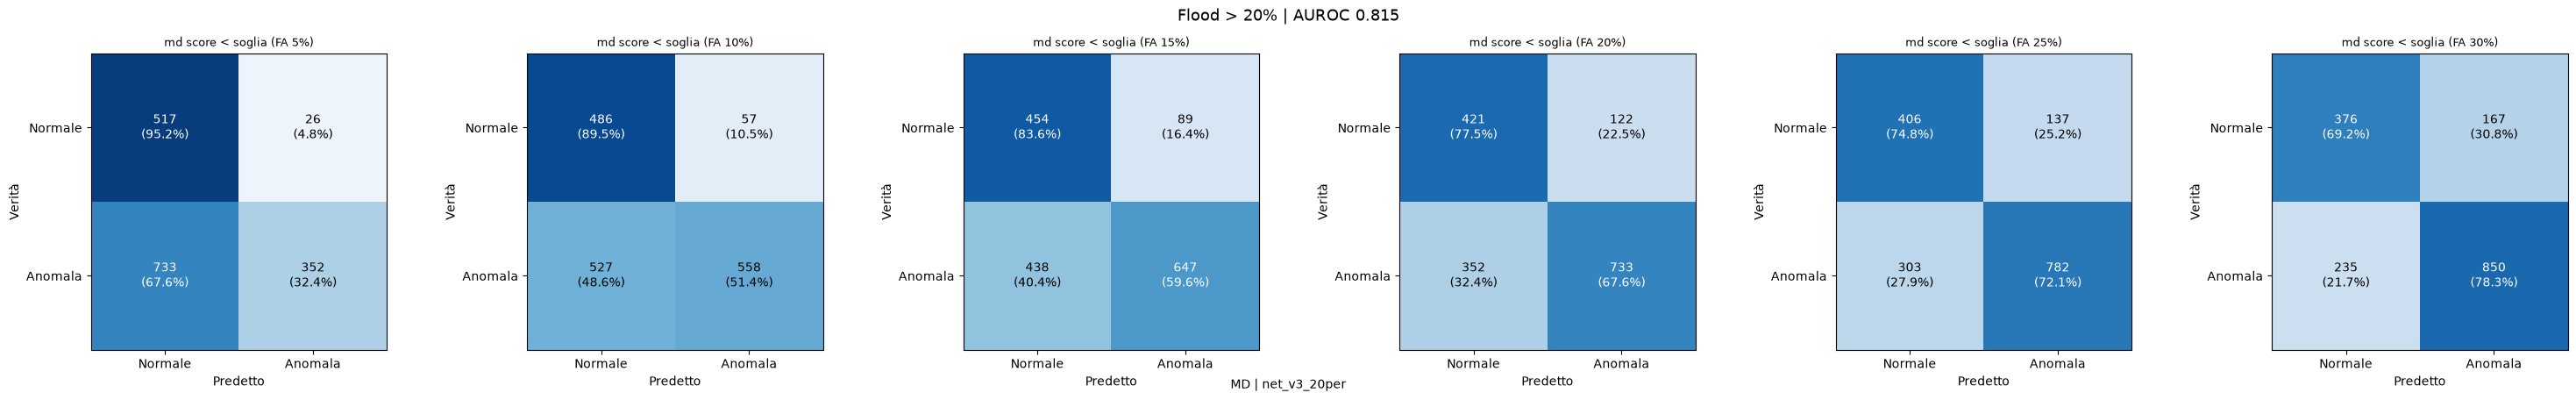

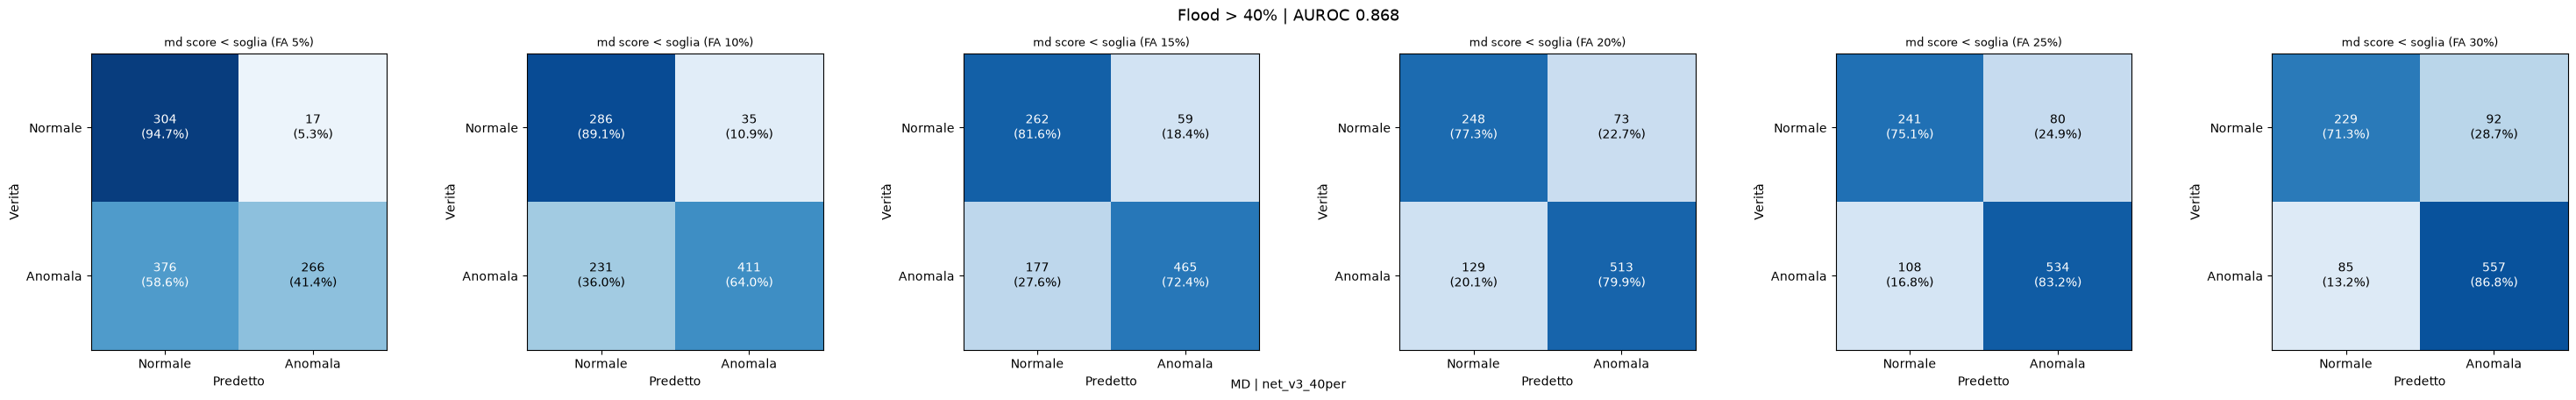

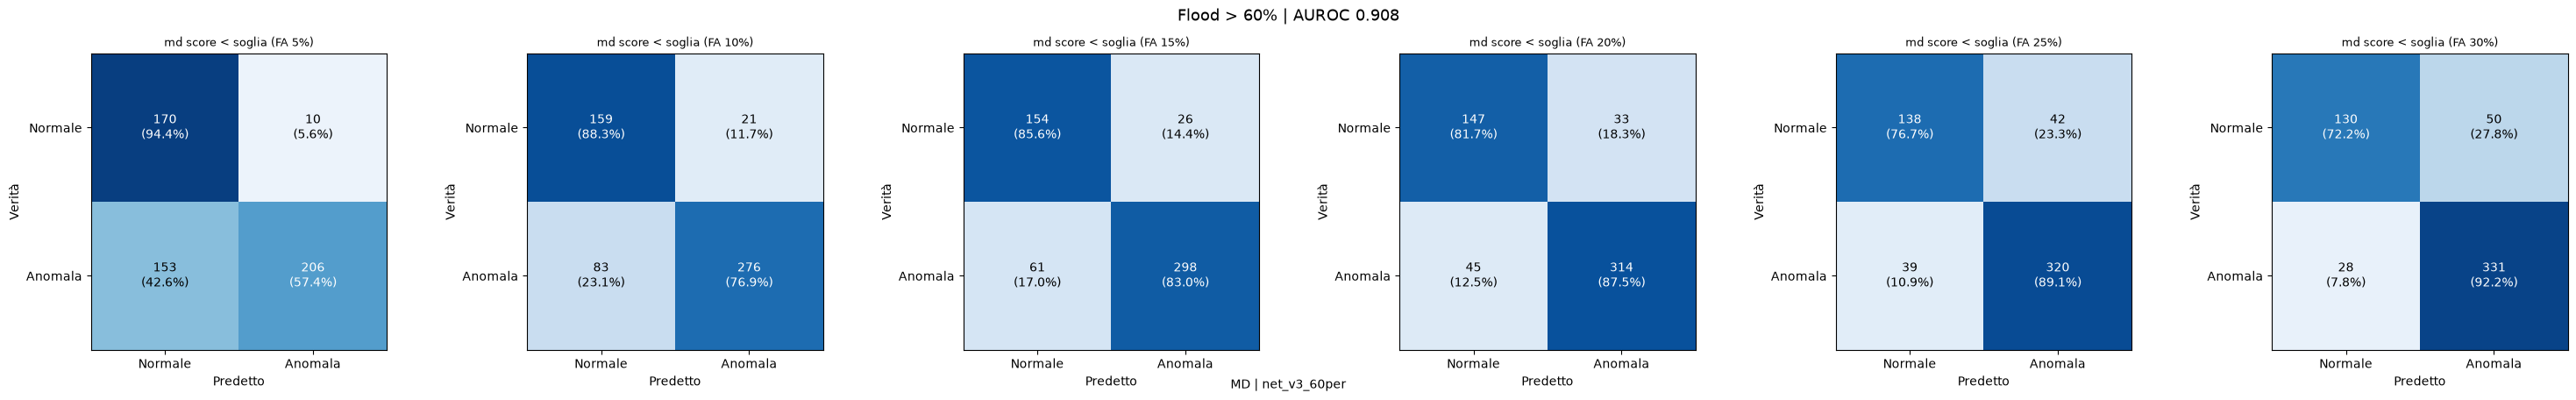

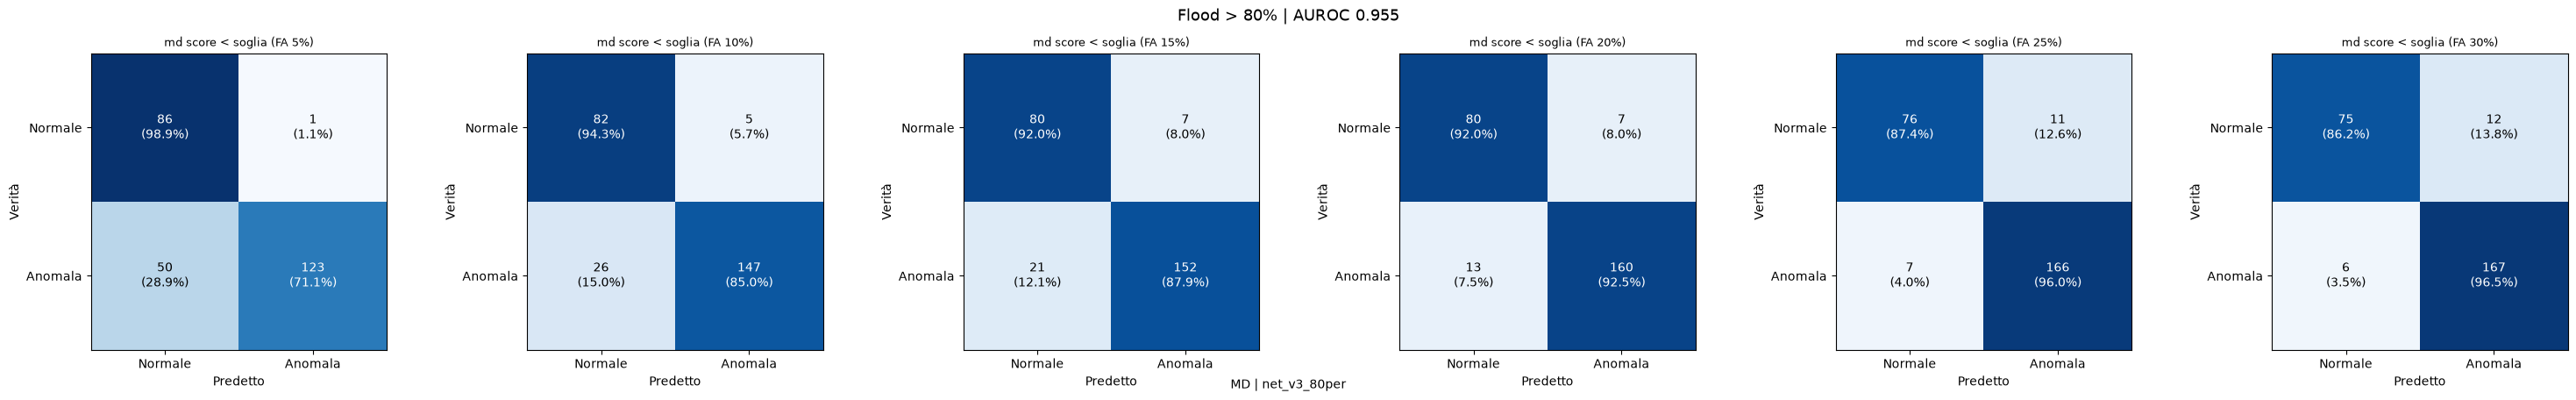

In [6]:
def plot_confusion(job_name, results):
    rules = results["rules"]
    fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

    for ax, (nome, r) in zip(axes[0], rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
    fig.text(0.5, 0.01, f"MD | {job_name}", ha="center", va="bottom", fontsize=10)
    plt.tight_layout()
    plt.show()


for job_name in job_names:
    results, df = load_job(job_name)
    plot_confusion(job_name, results)